# IMDB Movie Review Sentiment Analysis

**Goal:** Classify IMDB movie reviews as *positive* or *negative* using classical NLP and machine learning.

**Dataset:** IMDB reviews, 50k labeled reviews, binary sentiment.

**Workflow**

| # | Stage | Description |
|---|-------|-------------|
| 1 | Data loading and quality check | Shape, types, missing values, duplicates |
| 2 | Exploratory data analysis | Class balance, review length, frequent words |
| 3 | Text cleaning | HTML, brackets, special characters, stopwords |
| 4 | Normalization comparison | Basic vs Stemming vs Lemmatization |
| 5 | Train / validation / test split | Stratified 60 / 20 / 20 |
| 6 | Vectorizer + model comparison | BoW, TF-IDF, n-grams with LogReg, Naive Bayes, LinearSVC |
| 7 | Hyperparameter tuning | GridSearchCV with 5-fold CV |
| 8 | Final evaluation | One-time evaluation on the test set |
| 9 | Model interpretation | Most influential words |
| 10 | Threshold and calibration | Precision/recall trade-off, probability reliability |

**Evaluation metrics:** Accuracy, Precision, Recall, F1-score, ROC-AUC. F1-score is the main selection metric.

## 1. Setup and Imports

Libraries used for data handling, text processing, modeling, and visualization.

In [1]:
# 1. GENERAL SETUP AND UTILITIES
# os: file handling | re: regex | time: timing | warnings: warning control | joblib: save/load models
import os
import re
import time
import warnings
import joblib

# Hide warning messages to keep the notebook output clean
warnings.filterwarnings("ignore")


# 2. DATA HANDLING
import numpy as np
import pandas as pd

# Splits the data into train / validation / test sets
from sklearn.model_selection import train_test_split


# 3. DATA VISUALIZATION AND EXPLORATORY DATA ANALYSIS
import matplotlib.pyplot as plt
import seaborn as sns

# Counter: word frequencies | WordCloud: word cloud visuals | STOPWORDS: default stopword set
from collections import Counter
from wordcloud import WordCloud, STOPWORDS


# 4. TEXT PREPROCESSING
import nltk

# BeautifulSoup: HTML tag removal | ToktokTokenizer: tokenizer | stopwords, WordNetLemmatizer, PorterStemmer: text normalization tools
from bs4 import BeautifulSoup
from nltk.tokenize.toktok import ToktokTokenizer
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.stem.porter import PorterStemmer


# 5. TEXT FEATURE EXTRACTION
# CountVectorizer = Bag of Words | TfidfVectorizer = TF-IDF
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)


# 6. MODEL BUILDING AND PIPELINES
# clone: creates an unfitted copy of an estimator or pipeline
from sklearn.base import clone
from sklearn.pipeline import Pipeline

# Candidate classifiers: Logistic Regression, Multinomial Naive Bayes, Linear SVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC


# 7. MODEL VALIDATION AND HYPERPARAMETER TUNING
from sklearn.model_selection import (
    cross_val_predict,
    GridSearchCV,
    StratifiedKFold
)


# 8. MODEL EVALUATION
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    precision_recall_curve,
    classification_report,
    confusion_matrix,
    make_scorer,
    brier_score_loss,
    ConfusionMatrixDisplay
)


# 9. PROBABILITY CALIBRATION
from sklearn.calibration import (
    CalibratedClassifierCV,
    calibration_curve
)


# 10. CHECK DATA DIRECTORY
# List files in the parent directory to check where the data is located
print(os.listdir(".."))

['Adult Income', 'Bank Fraud', 'Car Insurance Claim Prediction(not finished)', 'CC General', 'Ecommerce', 'hotel_reservations_app', 'House Price India', 'IMDB Reviews', 'Loan Approval', 'Turbo.az', 'Wine clustering']


In [103]:
# Configure pandas display settings for better readability of DataFrames
pd.set_option("display.max_columns", None)   # Show all columns, no matter how many (don't truncate with "...")
pd.set_option("display.max_rows", 100)       # Show up to 100 rows before truncating output
pd.set_option("display.width", None)         # Auto-detect terminal/console width so columns aren't wrapped awkwardly
pd.set_option("display.max_colwidth", None)  # Show full content of each cell, even long strings, without cutting them off

## 2. Data Loading and Quality Check

First look at the dataset: its size, column types, missing values, and duplicate rows.

> Duplicate reviews are removed before splitting, so identical texts cannot appear in both the training and test sets.

In [2]:
# Load the IMDB dataset from a CSV file into a DataFrame
df = pd.read_csv(r"C:\Users\User\OneDrive\Desktop\Data Science\Projects\IMDB Reviews\imdb_dataset.csv")
# Display the DataFrame
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [61]:
# Number of rows and columns
df.shape

(50000, 2)

In [62]:
# Preview the first 5 rows
df.head(5)

,review,sentiment
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fact that it goes where other shows wouldn't dare. Forget pretty pictures painted for mainstream audiences, forget charm, forget romance...OZ doesn't mess around. The first episode I ever saw struck me as so nasty it was surreal, I couldn't say I was ready for it, but as I watched more, I developed a taste for Oz, and got accustomed to the high levels of graphic violence. Not just violence, but injustice (crooked guards who'll be sold out for a nickel, inmates who'll kill on order and get away with it, well mannered, middle class inmates being turned into prison bitches due to their lack of street skills or prison experience) Watching Oz, you may become comfortable with what is uncomfortable viewing....thats if you can get in touch with your darker side.",positive
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only ""has got all the polari"" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrificly written and performed piece. A masterful production about one of the great master's of comedy and his life. <br /><br />The realism really comes home with the little things: the fantasy of the guard which, rather than use the traditional 'dream' techniques remains solid then disappears. It plays on our knowledge and our senses, particularly with the scenes concerning Orton and Halliwell and the sets (particularly of their flat with Halliwell's murals decorating every surface) are terribly well done.",positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic, but the dialogue is witty and the characters are likable (even the well bread suspected serial killer). While some may be disappointed when they realize this is not Match Point 2: Risk Addiction, I thought it was proof that Woody Allen is still fully in control of the style many of us have grown to love.<br /><br />This was the most I'd laughed at one of Woody's comedies in years (dare I say a decade?). While I've never been impressed with Scarlet Johanson, in this she managed to tone down her ""sexy"" image and jumped right into a average, but spirited young woman.<br /><br />This may not be the crown jewel of his career, but it was wittier than ""Devil Wears Prada"" and more interesting than ""Superman"" a great comedy to go see with friends.",positive
3,"Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a soap opera... and suddenly, Jake decides to become Rambo and kill the zom

In [63]:
#Summary of the dataset
df.describe()

,review,sentiment
count,50000,50000
unique,49582,2
top,"Loved today's show!!! It was a variety and not solely cooking (which would have been great too). Very stimulating and captivating, always keeping the viewer peeking around the corner to see what was coming up next. She is as down to earth and as personable as you get, like one of us which made the show all the more enjoyable. Special guests, who are friends as well made for a nice surprise too. Loved the 'first' theme and that the audience was invited to play along too. I must admit I was shocked to see her come in under her time limits on a few things, but she did it and by golly I'll be writing those recipes down. Saving time in the kitchen means more time with family. Those who haven't tuned in yet, find out what channel and the time, I assure you that you won't be disappointed.",positive
freq,5,25000


In [64]:
# Column names, data types, non-null counts and memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [105]:
# Count missing values in each column
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [106]:
# Count fully duplicated rows
df.duplicated().sum()

np.int64(418)

In [107]:
# Remove duplicate rows and reset the index so it is continuous again
df = df.drop_duplicates().reset_index(drop=True)

## 3. Exploratory Data Analysis (EDA)

Questions answered in this section:
- Are the classes balanced?
- How long are the reviews, and are there extreme outliers?
- Which words are most common in each class?

In [68]:
#Sentiment count
df['sentiment'].value_counts()

sentiment
positive    24884
negative    24698
Name: count, dtype: int64

(49582, 2)
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


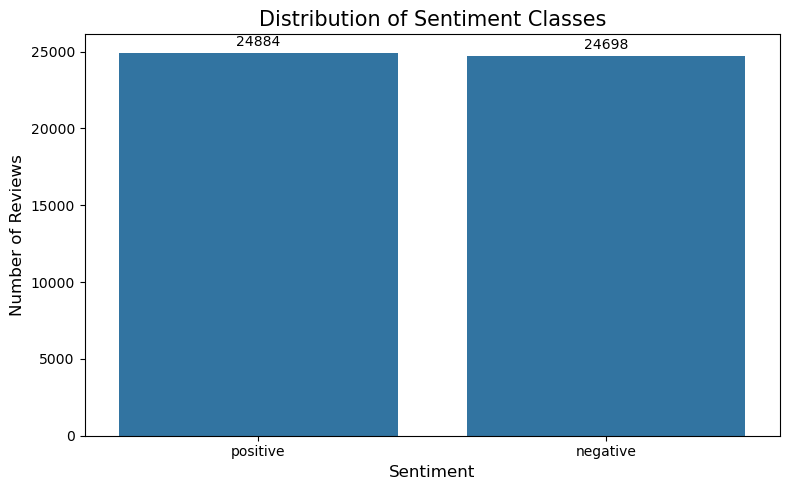

sentiment
positive    50.19
negative    49.81
Name: proportion, dtype: float64


In [69]:
# Check your dataset
print(df.shape)
print(df["sentiment"].value_counts())

# Plot sentiment distribution
plt.figure(figsize=(8, 5))

# Bar chart of review counts per sentiment class (ordered by frequency)
ax = sns.countplot(
    data=df,
    x="sentiment",
    order=df["sentiment"].value_counts().index
)

plt.title("Distribution of Sentiment Classes", fontsize=15)
plt.xlabel("Sentiment", fontsize=12)
plt.ylabel("Number of Reviews", fontsize=12)

# Add counts above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

# Print class percentages to check how balanced the data is
print((df["sentiment"].value_counts(normalize=True) * 100).round(2))

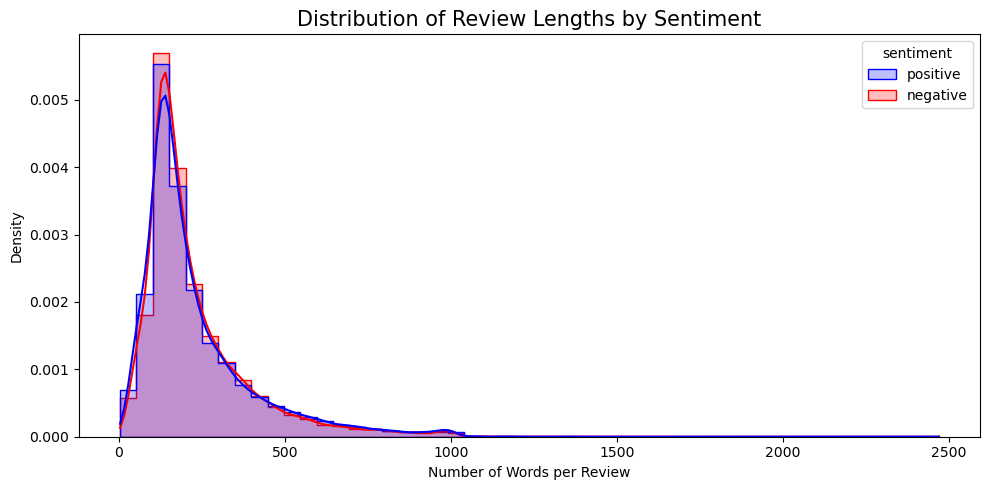

In [6]:
# Calculate review length in words
df["word_count"] = (
    df["review"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

# Histogram of review lengths
plt.figure(figsize=(10, 5))

# Overlaid density histograms per class (common_norm=False scales each class separately, kde adds a smooth curve)
sns.histplot(
    data=df,
    x="word_count",
    hue="sentiment",
    bins=50,
    kde=True,
    element="step",
    stat="density",
    common_norm=False,
    palette={"positive": "blue", "negative": "red"}
)

plt.title("Distribution of Review Lengths by Sentiment", fontsize=15)
plt.xlabel("Number of Words per Review")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


             chars   words  avg_word_len  exclamations  questions  caps_words
sentiment                                                                    
negative   1294.06  229.46          5.62          1.03       0.91        2.11
positive   1324.80  232.85          5.65          0.94       0.39        1.83


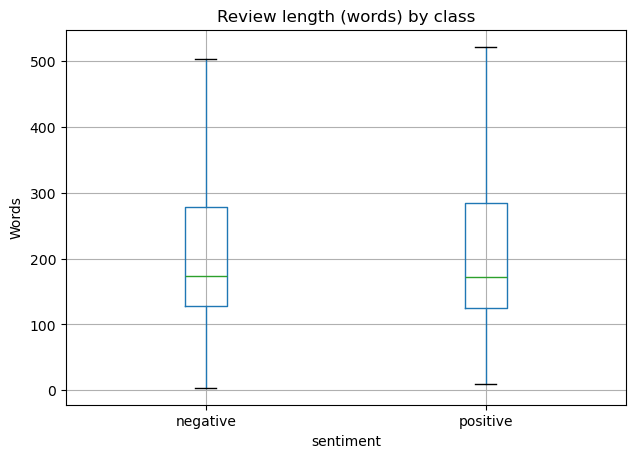

In [3]:
# Raw (uncleaned) review text, stored as strings
raw = df['review'].astype(str)

# Table of simple text statistics for every review
eda = pd.DataFrame({'sentiment': df['sentiment']})
# Number of characters
eda['chars'] = raw.str.len()
# Number of words
eda['words'] = raw.str.split().str.len()
# Average word length (0-word reviews become NaN to avoid division by zero)
eda['avg_word_len'] = eda['chars'] / eda['words'].replace(0, np.nan)
# Number of exclamation marks
eda['exclamations'] = raw.str.count('!')
# Number of question marks
eda['questions'] = raw.str.count(r'\?')
# Number of ALL-CAPS words (longer than 1 character)
eda['caps_words'] = raw.apply(lambda t: sum(w.isupper() and len(w) > 1 for w in t.split()))

# Average of each statistic per sentiment class
print(eda.groupby('sentiment').mean(numeric_only=True).round(2))

# Boxplot of review length per class (outliers hidden for readability)
eda.boxplot(column='words', by='sentiment', figsize=(7, 5), showfliers=False)
plt.title('Review length (words) by class')
plt.suptitle('')
plt.ylabel('Words')
plt.show()

In [4]:
# Share of raw reviews that contain each type of noise
noise = pd.Series({
    'Contains HTML tags': raw.str.contains(r'<[^>]+>').mean(),
    'Contains [brackets]': raw.str.contains(r'\[[^\]]*\]').mean(),
    'Contains URLs': raw.str.contains(r'http\S+|www\.\S+').mean(),
    'Contains digits': raw.str.contains(r'\d').mean(),
    'Contains non-ASCII chars': raw.apply(lambda t: not t.isascii()).mean(),
})
# Show the shares as percentages
print((noise * 100).round(2).astype(str) + ' %')

Contains HTML tags           58.4 %
Contains [brackets]          0.32 %
Contains URLs                0.39 %
Contains digits             56.01 %
Contains non-ASCII chars     9.32 %
dtype: object


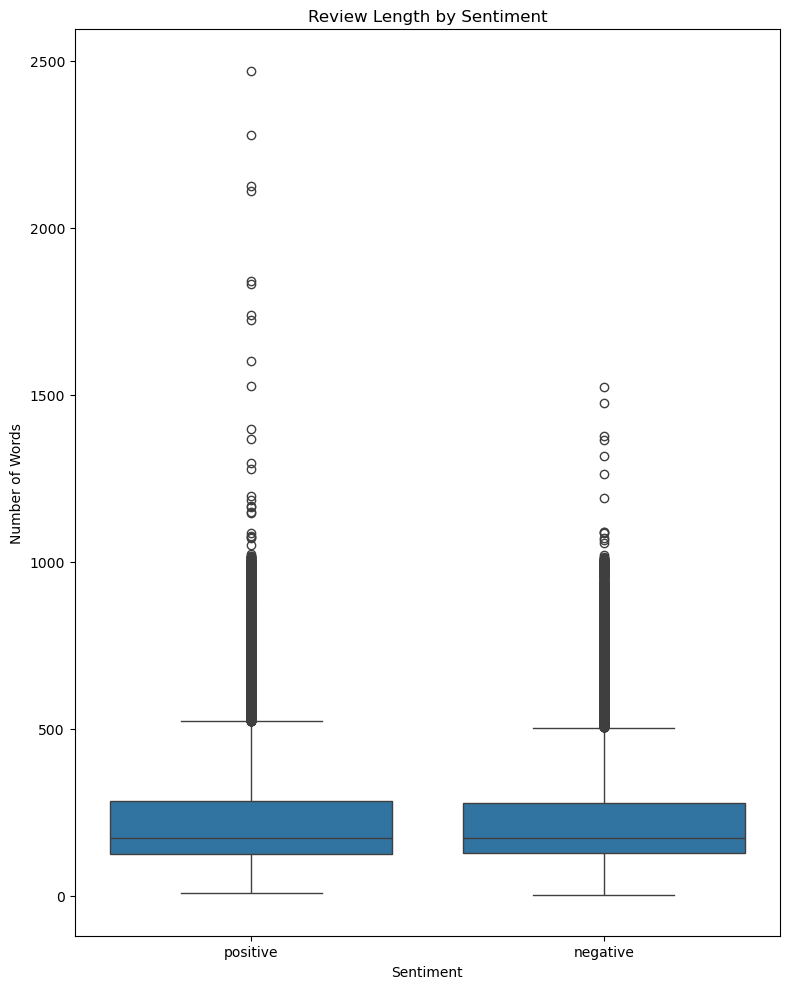

In [71]:
plt.figure(figsize=(8, 10))

# Boxplot comparing the review length distribution of each sentiment
sns.boxplot(
    data=df,
    x="sentiment",
    y="word_count"
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()

In [74]:
# Check the first review
print(df["review"].iloc[0])

# Check missing values
print(df[["review", "sentiment"]].isnull().sum())

# Check sentiment distribution
print(df["sentiment"].value_counts())

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fac

In [75]:
# One-time download of the NLTK stopword list (uncomment on first run)
#nltk.download('stopwords')

In [76]:
# One-time download of the WordNet dictionary used by the lemmatizer (uncomment on first run)
#nltk.download("wordnet")

In [77]:
# One-time download of the Open Multilingual WordNet data (uncomment on first run)
#nltk.download("omw-1.4")

## 4. Text Cleaning

Cleaning is applied to the whole dataset before splitting. These steps are **stateless** (they learn nothing from the data), so they cannot cause data leakage.

| Step | Purpose |
|------|---------|
| HTML stripping | Removes tags such as `<br />`, with a space separator so words do not merge |
| Square-bracket removal | Removes noisy text like `[spoiler]` |
| Special-character removal | Keeps letters and digits only |
| Lowercasing | Treats "Good" and "good" as the same token |
| Stopword removal | Removes common, low-information words |

**Important decision:** negation words (`not`, `no`, `nor`, ...) are **kept**. The standard NLTK stopword list contains them, but removing them would turn *"not good"* into *"good"* and flip the sentiment.

In [108]:
#Removing the html strips
def strip_html(text):
    # Parse the HTML so tags can be dropped
    soup = BeautifulSoup(text, "html.parser")
    return soup.get_text(separator=" ")  # separator keeps words apart after <br /> tags

#Removing the square brackets
def remove_between_square_brackets(text):
    # Delete everything inside square brackets, including the brackets
    return re.sub(r'\[[^]]*\]', '', text)

#Removing the noisy text
def denoise_text(text):
    # Step 1: remove HTML tags
    text = strip_html(text)
    # Step 2: remove [bracketed] text
    text = remove_between_square_brackets(text)
    return text

#Apply function on review column
df['review'] = df['review'].apply(denoise_text)

In [109]:
#Define function for removing special characters
def remove_special_characters(text, remove_digits=False):
    text = text.replace("'", "")  # don't -> dont (avoids a stray "t" token)
    # Keep only letters and digits (digits are also removed when remove_digits=True)
    pattern = r'[^a-zA-Z\s]' if remove_digits else r'[^a-zA-Z0-9\s]'
    return re.sub(pattern, ' ', text)  # space instead of '' so "well-made" doesn't become "wellmade"

#Apply function on review column
df['review'] = df['review'].apply(remove_special_characters)

In [110]:
#Tokenization of text
tokenizer = ToktokTokenizer()

#Setting English stopwords (negations are kept because they carry sentiment)
negations = {'not', 'no', 'nor', 'never', "don't", "didn't", "isn't", "wasn't"}
# NLTK English stopwords minus the negation words
stopword_list = set(stopwords.words('english')) - negations

In [111]:
#removing the stopwords
def remove_stopwords(text, is_lower_case=False):
    if not is_lower_case:
        text = text.lower()
    # Split the text into tokens and trim whitespace
    tokens = [token.strip() for token in tokenizer.tokenize(text)]
    # Keep only tokens that are not stopwords
    filtered_tokens = [token for token in tokens if token not in stopword_list]
    # Rebuild the cleaned text as one string
    return ' '.join(filtered_tokens)

#Apply function on review column
df['review'] = df['review'].apply(remove_stopwords)

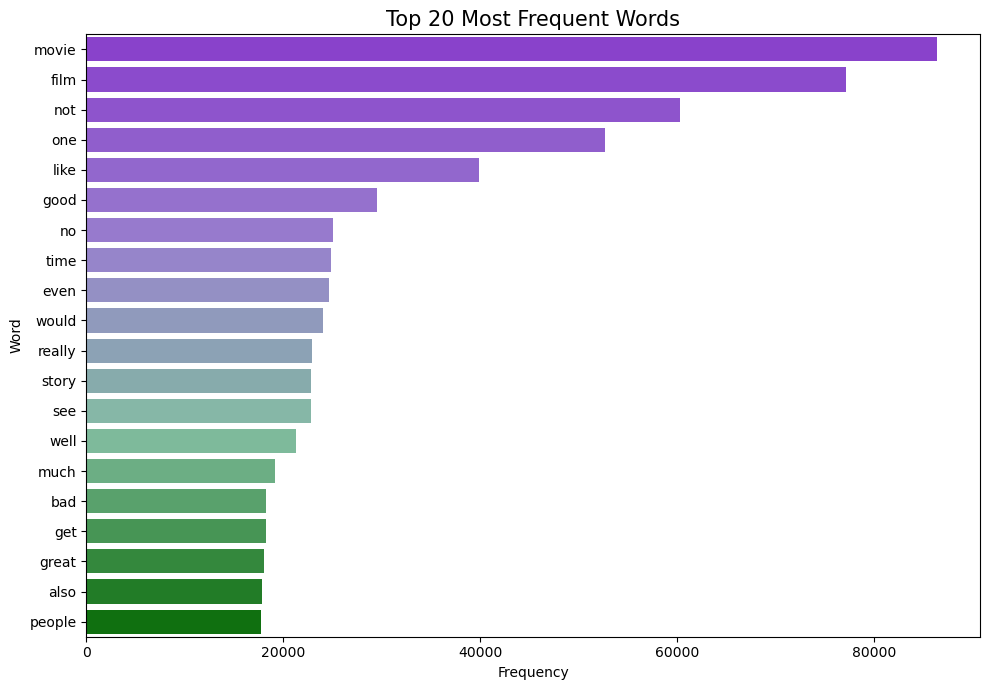

In [112]:
# Change this to your actual preprocessed text column
TEXT_COL = "review"

# Combine the processed reviews
all_text = " ".join(
    df[TEXT_COL]
    .dropna()
    .astype(str)
)

# Extract words
words = re.findall(r"\b[a-zA-Z]+\b", all_text.lower())

# Count word frequencies
word_counts = Counter(words)

# Select the 20 most frequent words
top_words = word_counts.most_common(20)

# Put the top words into a DataFrame for plotting
freq_df = pd.DataFrame(
    top_words,
    columns=["word", "frequency"]
)

# Purple-to-green color gradient, one color per bar
palette = sns.blend_palette(
    ["#8A2BE2", "#9370DB", "#7BC8A4", "#008000"],
    n_colors=len(top_words)
)

# Plot
plt.figure(figsize=(10, 7))
sns.barplot(
    data=freq_df,
    x="frequency",
    y="word",
    palette=palette
)

plt.title("Top 20 Most Frequent Words", fontsize=15)
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

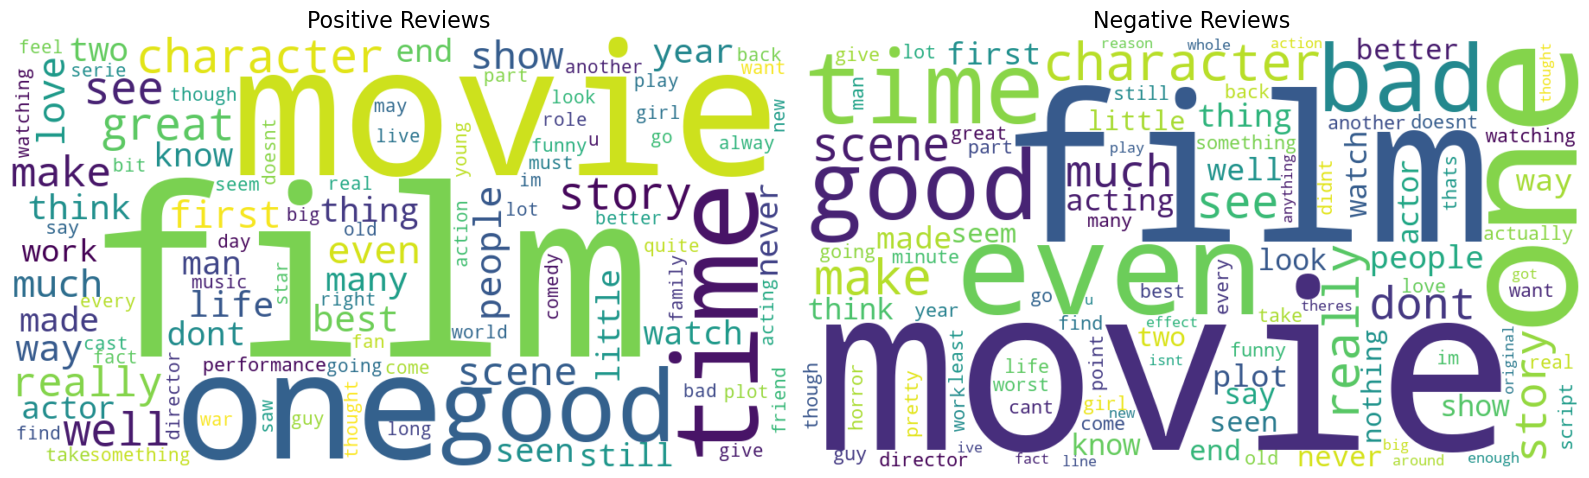

In [113]:
TEXT_COL = "review"

# Separate reviews by sentiment
positive_text = " ".join(
    df.loc[
        df["sentiment"].str.lower() == "positive",
        TEXT_COL
    ].dropna().astype(str)
)

negative_text = " ".join(
    df.loc[
        df["sentiment"].str.lower() == "negative",
        TEXT_COL
    ].dropna().astype(str)
)

# Generate word clouds
positive_wc = WordCloud(
    width=900,
    height=500,
    background_color="white",
    max_words=100,
    collocations=False
).generate(positive_text)

negative_wc = WordCloud(
    width=900,
    height=500,
    background_color="white",
    max_words=100,
    collocations=False
).generate(negative_text)

# Display side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: positive reviews
axes[0].imshow(positive_wc, interpolation="bilinear")
axes[0].set_title("Positive Reviews", fontsize=16)
axes[0].axis("off")

# Right: negative reviews
axes[1].imshow(negative_wc, interpolation="bilinear")
axes[1].set_title("Negative Reviews", fontsize=16)
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Number of unique words in a collection of texts
def vocab_size(series):
    return len(set(w for t in series for w in t.split()))

# Compare raw vs cleaned text: average review length and vocabulary size
summary = pd.DataFrame({
    'Avg words per review': [raw.str.split().str.len().mean(),
                             df['review'].str.split().str.len().mean()],
    'Vocabulary size': [vocab_size(raw.str.lower()), vocab_size(df['review'])],
}, index=['Raw', 'Cleaned']).round(1)
print(summary)

         Avg words per review  Vocabulary size
Raw                     231.2           390931
Cleaned                 231.2           438729


In [8]:
text_col = 'review'   # your cleaned column
# Label used for the positive class (string or 1 depending on the dataset)
positive_label = "positive" if "positive" in df['sentiment'].unique() else 1

# Return the n most frequent n-grams (single words or word pairs) in a collection of texts
def top_ngrams(texts, ngram_range=(1, 1), n=15):
    # Count n-gram occurrences
    cv = CountVectorizer(ngram_range=ngram_range)
    X = cv.fit_transform(texts)
    # Total count of each n-gram across all reviews
    counts = np.asarray(X.sum(axis=0)).ravel()
    # Positions of the n most frequent n-grams
    idx = counts.argsort()[::-1][:n]
    return pd.Series(counts[idx], index=cv.get_feature_names_out()[idx])

# Show the top words and bigrams for each sentiment class
for label in df['sentiment'].unique():
    # Reviews that belong to the current class
    sub = df.loc[df['sentiment'] == label, text_col]
    print(f"\n=== {label}: top words ===")
    print(top_ngrams(sub, (1, 1)))
    print(f"\n=== {label}: top bigrams ===")
    print(top_ngrams(sub, (2, 2)))


=== positive: top words ===
the     341281
and     176634
of      152105
to      131322
is      111830
in       99250
br       97954
it       95133
this     69648
that     69593
as       51106
with     45718
for      44236
was      43339
film     42110
dtype: int64

=== positive: top bigrams ===
br br         49041
of the        41605
in the        25745
the film      14656
and the       14430
this movie    13523
to the        12811
it is         11549
this film     10904
the movie     10411
this is       10152
to be         10131
one of         9622
on the         9088
with the       8244
dtype: int64

=== negative: top words ===
the      326712
and      147807
of       137305
to       136802
br       103997
is        99252
it        95724
in        87531
this      81354
that      74286
was       52269
movie     50117
for       43235
but       42825
with      41650
dtype: int64

=== negative: top bigrams ===
br br         52047
of the        35654
in the        24507
this movie    18

In [82]:
# Display the cleaned DataFrame
df

,review,sentiment,word_count
0,one reviewers mentioned watching 1 oz episode youll hooked right exactly happened first thing struck oz brutality unflinching scenes violence set right word go trust not show faint hearted timid show pulls no punches regards drugs sex violence hardcore classic use word called oz nickname given oswald maximum security state penitentary focuses mainly emerald city experimental section prison cells glass fronts face inwards privacy not high agenda em city home many aryans muslims gangstas latinos christians italians irish scuffles death stares dodgy dealings shady agreements never far away would say main appeal show due fact goes shows wouldnt dare forget pretty pictures painted mainstream audiences forget charm forget romance oz doesnt mess around first episode ever saw struck nasty surreal couldnt say ready watched developed taste oz got accustomed high levels graphic violence not violence injustice crooked guards wholl sold nickel inmates wholl kill order get away well mannered middle class inmates turned prison bitches due lack street skills prison experience watching oz may become comfortable uncomfortable viewing thats get touch darker side,positive,307
1,wonderful little production filming technique unassuming old time bbc fashion gives comforting sometimes discomforting sense realism entire piece actors extremely well chosen michael sheen not got polari voices pat truly see seamless editing guided references williams diary entries not well worth watching terrificly written performed piece masterful production one great masters comedy life realism really comes home little things fantasy guard rather use traditional dream techniques remains solid disappears plays knowledge senses particularly scenes concerning orton halliwell sets particularly flat halliwells murals decorating every surface terribly well done,positive,162
2,thought wonderful way spend time hot summer weekend sitting air conditioned theater watching light hearted comedy plot simplistic dialogue witty characters likable even well bread suspected serial killer may disappointed realize not match point 2 risk addiction thought proof woody allen still fully control style many us grown love id laughed one woodys comedies years dare say decade ive never impressed scarlet johanson managed tone sexy image jumped right average spirited young woman may not crown jewel career wittier devil wears prada interesting superman great comedy go see friends,positive,166
3,basically theres family little boy jake thinks theres zombie closet parents fighting time movie slower soap opera suddenly jake decides become rambo kill zombie ok first youre going make film must decide thriller drama drama movie watchable parents divorcing arguing like real life jake closet totally ruins film expected see boogeyman similar movie instead watched drama meaningless thriller spots 3 10 well playing parents descent dialogs shots jake ignore,negative,138
4,petter matteis love time money visually stunning film watch mr mattei offers us vivid portrait human relations movie seems telling us money power success people different situations encounter variation arthur schnitzlers play theme director transfers action present time new york different characters meet connect one connected one way another next person no one seems know previous point contact stylishly film sophisticated luxurious look taken see people live world live habitat thing one gets souls picture different stages loneliness one inhabits big city not exactly best place human relations find sincere fulfillment one discerns case people encounter acting good mr matteis direction steve buscemi rosario dawson carol kane michael imperioli adrian grenier rest talented cast make characters come alive wish mr mattei good luck await anxiously next work,positive,230
...,...,...,...
49577,thought movie right good job wasnt creative original first expecting whole lotta fun think like comes dvd im going pay money proudly

## 5. Normalization Comparison

Three normalization strategies are compared using TF-IDF (1-2 grams) + Logistic Regression:

| Method | Description | Example |
|--------|-------------|---------|
| **Basic** | Text is left unchanged | *running movies* |
| **Stemming** | Words are cut to a root (Porter) | *run movi* |
| **Lemmatization** | Words are mapped to dictionary forms (WordNet) | *running movie* |

All methods are evaluated on the **same** train/validation rows, so the comparison is fair.

> Lemmatization without POS tags treats every word as a noun, so it often changes very little.

In [83]:
# Normalization tools: WordNet lemmatizer and Porter stemmer
lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()


# Basic: keep the text unchanged (only convert to string)
def preprocess_basic(text):
    return str(text)

# Lemmatization: map each word to its dictionary form
def preprocess_lemmatization(text):
    return " ".join(
        lemmatizer.lemmatize(word)
        for word in str(text).split()
    )

# Stemming: cut each word down to its root
def preprocess_stemming(text):
    return " ".join(
        stemmer.stem(word)
        for word in str(text).split()
    )

In [84]:
# Demo on a sample sentence to see how each method behaves
sample = "The movies were amazing, and the actors were running!"

print("Basic:", preprocess_basic(sample))
print("Lemmatization:", preprocess_lemmatization(sample))
print("Stemming:", preprocess_stemming(sample))

Basic: The movies were amazing, and the actors were running!
Lemmatization: The movie were amazing, and the actor were running!
Stemming: the movi were amazing, and the actor were running!


In [85]:
# Map each method name to its function
preprocessors = {
    "Basic": preprocess_basic,
    "Lemmatization": preprocess_lemmatization,
    "Stemming": preprocess_stemming
}

# Apply every preprocessing method to the whole dataset BEFORE splitting.
# These steps are stateless (they learn nothing from the data), so there is no leakage.
for name, preprocess in preprocessors.items():
    df[name] = df["review"].apply(preprocess)

## 6. Train / Validation / Test Split

| Set | Share | Use |
|-----|-------|-----|
| Train | 60% | Fit vectorizers and models |
| Validation | 20% | Compare approaches |
| Test | 20% | Final, one-time evaluation |

The split is **stratified**, so the class ratio is the same in every set. `random_state=42` makes it reproducible.

**Rule used throughout:** anything that learns from data (vectorizer, model) is fitted on training data only. `Pipeline` guarantees this.

In [86]:
# Split once, so all three methods are evaluated on exactly the same rows
# 80% train + validation, 20% test (stratified keeps the class ratio)
train_val_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["sentiment"]
)
# Split train + validation 75/25, which gives 60% train and 20% validation of the full data
train_df, val_df = train_test_split(
    train_val_df, test_size=0.25, random_state=42,
    stratify=train_val_df["sentiment"]
)

# Target labels of each set
y_train = train_df["sentiment"]
y_val = val_df["sentiment"]
y_test = test_df["sentiment"]

# Text of each normalization method for train and validation
X_train_processed = {name: train_df[name] for name in preprocessors}
X_val_processed = {name: val_df[name] for name in preprocessors}

# Show the first training review under each normalization method
print(X_train_processed["Basic"].iloc[0])
print(X_train_processed["Lemmatization"].iloc[0])
print(X_train_processed["Stemming"].iloc[0])

# Shapes of the three sets
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

# Number of samples in each set
print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

# Check that the class balance is preserved in every set
print("\nTraining distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True))

print("\nTest distribution:")
print(y_test.value_counts(normalize=True))

wow probably worst dcom ever watched first half hour laughed brenda song plays wendy popular girl hot jock boyfriend stuck friends determined homecoming queen supposed save world warrior shin comes aid help martial arts shin teaches skills snake tiger etc learn certain techniques save world movie great kids want learn martial arts chinese culture acting casting horrible brenda song comedic actress cant see playing serious role laugh loud funny watching cry shin shin couldnt act everything totally unbelievable watched movie tried think something similar thing came power rangers movie fake stunts power ranger esquire corny stupid characters werent likable couldnt stand watch disney really needs take time make decent movies high school musical movie deserves disney channel along movies like jumping ship color friendship go figure read weep stuck suburbs like action adventure corny jokes youll like movie
wow probably worst dcom ever watched first half hour laughed brenda song play wendy po

In [87]:
# Collects metrics for each normalization method
results = []
trained_models = {}  # now stores full pipelines (vectorizer + model)

# Identify the positive class
positive_label = (
    "positive"
    if "positive" in y_train.unique()
    else 1
)

# Pipeline: TF-IDF (unigrams + bigrams) followed by Logistic Regression
def build_pipeline():
    return Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=100000
        )),
        ("clf", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

# Evaluate each normalization method with the same model on the validation set
for name in preprocessors:

    # 1-2. Vectorize + train the same classifier (the vectorizer is fit on train only)
    pipe = build_pipeline()
    pipe.fit(X_train_processed[name], y_train)

    # 3. Predict validation labels
    y_pred = pipe.predict(X_val_processed[name])

    # 4. Get probability of the positive class
    positive_index = list(pipe.classes_).index(positive_label)
    y_prob = pipe.predict_proba(X_val_processed[name])[:, positive_index]

    # 5. Calculate evaluation metrics
    results.append({
        "Method": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred,
            pos_label=positive_label,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred,
            pos_label=positive_label,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_pred,
            pos_label=positive_label,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_val == positive_label).astype(int),
            y_prob
        )
    })

    # Save fitted pipeline
    trained_models[name] = pipe

# Display comparison
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
)

print(results_df.round(4))

          Method  Accuracy  Precision  Recall  F1-score  ROC-AUC
0          Basic    0.8980     0.8873  0.9126    0.8998   0.9638
1  Lemmatization    0.8980     0.8882  0.9114    0.8996   0.9623
2       Stemming    0.8972     0.8886  0.9092    0.8988   0.9618


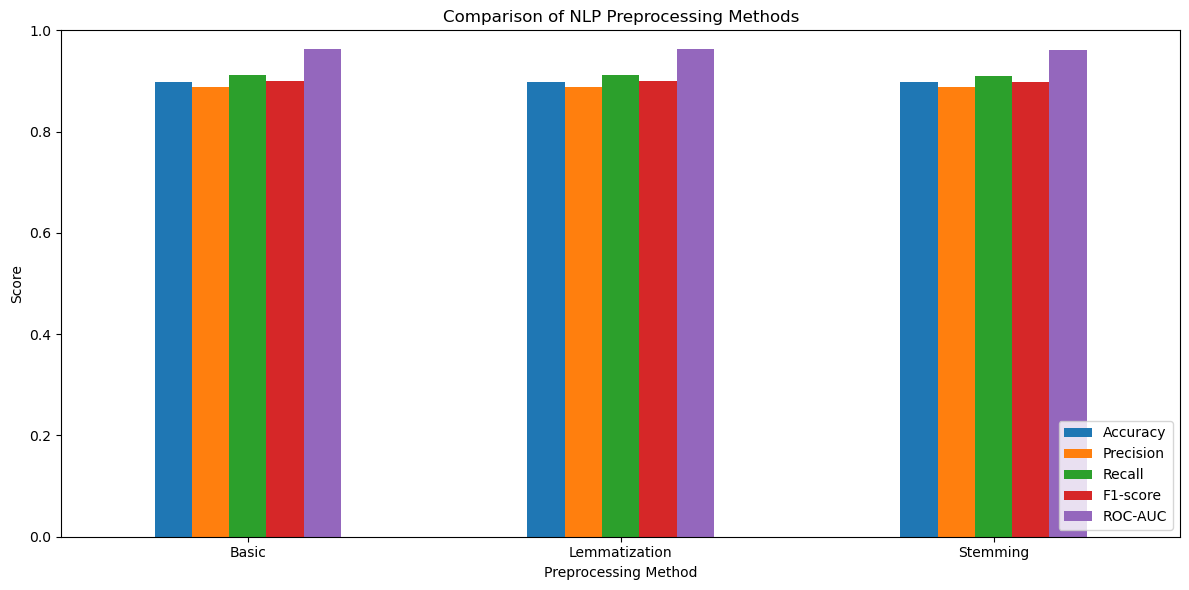

In [88]:
# Metrics to plot
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]

# Grouped bar chart comparing the normalization methods
results_df.plot(
    x="Method",
    y=metrics,
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of NLP Preprocessing Methods")
plt.ylabel("Score")
plt.xlabel("Preprocessing Method")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [89]:
# Select the best validation result
best_method = results_df.iloc[0]["Method"]
best_preprocessor = preprocessors[best_method]  # kept for preprocessing new raw text at inference time

print("Selected method:", best_method)

# Combine training and validation data (already preprocessed, just pick the column)
X_train_final_clean = pd.concat([train_df[best_method], val_df[best_method]])
y_train_final = pd.concat([y_train, y_val])
X_test_final_clean = test_df[best_method]

# Fit the final pipeline (vectorizer + model) on train + validation
final_pipeline = build_pipeline()
final_pipeline.fit(X_train_final_clean, y_train_final)

# Evaluate on the test set
y_test_pred = final_pipeline.predict(X_test_final_clean)

# Precision, recall and F1-score per class on the test set
print(classification_report(y_test, y_test_pred))

Selected method: Basic
              precision    recall  f1-score   support

    negative       0.91      0.89      0.90      4940
    positive       0.89      0.92      0.90      4977

    accuracy                           0.90      9917
   macro avg       0.90      0.90      0.90      9917
weighted avg       0.90      0.90      0.90      9917



In [90]:
# Text of the selected normalization method for train and validation
X_train_text = train_df[best_method]
X_val_text = val_df[best_method]

### Normalization Result

**Selected method: Basic.**

Reason: it achieved the highest validation scores across [F1-score / Accuracy / ROC-AUC]. Forms such as *loved* and *loving* can carry sentiment information that stemming removes.

## 7. Vectorizer + Model Comparison

### Vectorizers

| Vectorizer | Description |
|-----------|-------------|
| **BoW** | Raw word counts (`CountVectorizer`) |
| **TF-IDF** | Counts reweighted so very common words matter less (`TfidfVectorizer`) |
| **BoW + n-grams** | Word counts for single words and word pairs, e.g. *not good* |
| **TF-IDF + n-grams** | TF-IDF weights for single words and word pairs |

### Models

| Model | Why it is included |
|-------|-------------------|
| **Logistic Regression** | Strong, interpretable baseline for text |
| **Multinomial Naive Bayes** | Very fast, works well with word counts |
| **Linear SVC** | Usually among the best linear models on sparse text |

This gives **4 x 3 = 12 combinations**. Each is fitted on the training set and scored on the validation set.

**Note:** `LinearSVC` has no `predict_proba`, so its ROC-AUC is computed from `decision_function`.

In [91]:
# Factories (lambdas) so every call creates a fresh, unfitted vectorizer; n-gram versions use unigrams + bigrams
vectorizer_factories = {
    "BoW":              lambda: CountVectorizer(min_df=2, max_features=100000),
    "TF-IDF":           lambda: TfidfVectorizer(min_df=2, max_features=100000),
    "BoW + n-grams":    lambda: CountVectorizer(ngram_range=(1, 2), min_df=2, max_features=100000),
    "TF-IDF + n-grams": lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=100000),
}

# Candidate classifiers
model_factories = {
    "LogReg":     lambda: LogisticRegression(max_iter=2000, random_state=42),
    "NaiveBayes": lambda: MultinomialNB(),
    "LinearSVC":  lambda: LinearSVC(random_state=42),
}

# Build a Pipeline (vectorizer + classifier) from a vectorizer name and a model name
def build_pipeline(vec_name, model_name):
    return Pipeline([
        ("vec", vectorizer_factories[vec_name]()),
        ("clf", model_factories[model_name]()),
    ])

# LinearSVC has no predict_proba, so ROC-AUC uses decision_function for it
def get_positive_scores(pipe, X):
    # Models with probabilities: use the probability of the positive class
    if hasattr(pipe, "predict_proba"):
        idx = list(pipe.classes_).index(positive_label)
        return pipe.predict_proba(X)[:, idx]
    scores = pipe.decision_function(X)  # score of classes_[1]
    return scores if pipe.classes_[1] == positive_label else -scores

In [92]:
# Stores validation metrics and fitted pipelines for every combination
comparison = []
fitted_pipelines = {}

# Try every vectorizer + model combination
for vec_name in vectorizer_factories:
    for model_name in model_factories:
        # Start the timer
        start = time.time()

        # Fit on training data only
        pipe = build_pipeline(vec_name, model_name)
        pipe.fit(X_train_text, y_train)

        # Predict validation labels and positive-class scores
        y_pred = pipe.predict(X_val_text)
        y_score = get_positive_scores(pipe, X_val_text)

        # Save validation metrics and total time
        comparison.append({
            "Vectorizer": vec_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_val, y_pred),
            "Precision": precision_score(y_val, y_pred, pos_label=positive_label, zero_division=0),
            "Recall": recall_score(y_val, y_pred, pos_label=positive_label, zero_division=0),
            "F1-score": f1_score(y_val, y_pred, pos_label=positive_label, zero_division=0),
            "ROC-AUC": roc_auc_score((y_val == positive_label).astype(int), y_score),
            "Time (s)": time.time() - start,
        })
        # Keep the fitted pipeline
        fitted_pipelines[(vec_name, model_name)] = pipe
        print(f"Done: {vec_name} + {model_name}")

# Rank the combinations by F1-score
comparison_df = (
    pd.DataFrame(comparison)
    .sort_values(by="F1-score", ascending=False)
    .reset_index(drop=True)
)
print(comparison_df.round(4))

Done: BoW + LogReg
Done: BoW + NaiveBayes
Done: BoW + LinearSVC
Done: TF-IDF + LogReg
Done: TF-IDF + NaiveBayes
Done: TF-IDF + LinearSVC
Done: BoW + n-grams + LogReg
Done: BoW + n-grams + NaiveBayes
Done: BoW + n-grams + LinearSVC
Done: TF-IDF + n-grams + LogReg
Done: TF-IDF + n-grams + NaiveBayes
Done: TF-IDF + n-grams + LinearSVC
          Vectorizer       Model  Accuracy  Precision  Recall  F1-score  \
0   TF-IDF + n-grams   LinearSVC    0.9064     0.9018  0.9130    0.9073   
1      BoW + n-grams      LogReg    0.8993     0.8961  0.9042    0.9001   
2   TF-IDF + n-grams      LogReg    0.8980     0.8873  0.9126    0.8998   
3             TF-IDF   LinearSVC    0.8935     0.8871  0.9028    0.8948   
4             TF-IDF      LogReg    0.8915     0.8806  0.9068    0.8935   
5      BoW + n-grams   LinearSVC    0.8910     0.8871  0.8969    0.8920   
6   TF-IDF + n-grams  NaiveBayes    0.8834     0.8811  0.8875    0.8843   
7                BoW      LogReg    0.8811     0.8762  0.8887    0

### Comparison Result

| Rank | Vectorizer | Model | F1-score |
|------|-----------|-------|----------|
| 1 | TF-IDF + n-grams | LinearSVC | 0.9073 |
| 2 | BoW + n-grams | LogisticRegression | 0.9001 |
| 3 | TF-IDF + n-grams | LogisticRegression | 0.8998 |

**Observations**
- Which vectorizer worked best and whether n-grams helped
- Which model family performed best
- Any notable training-time differences

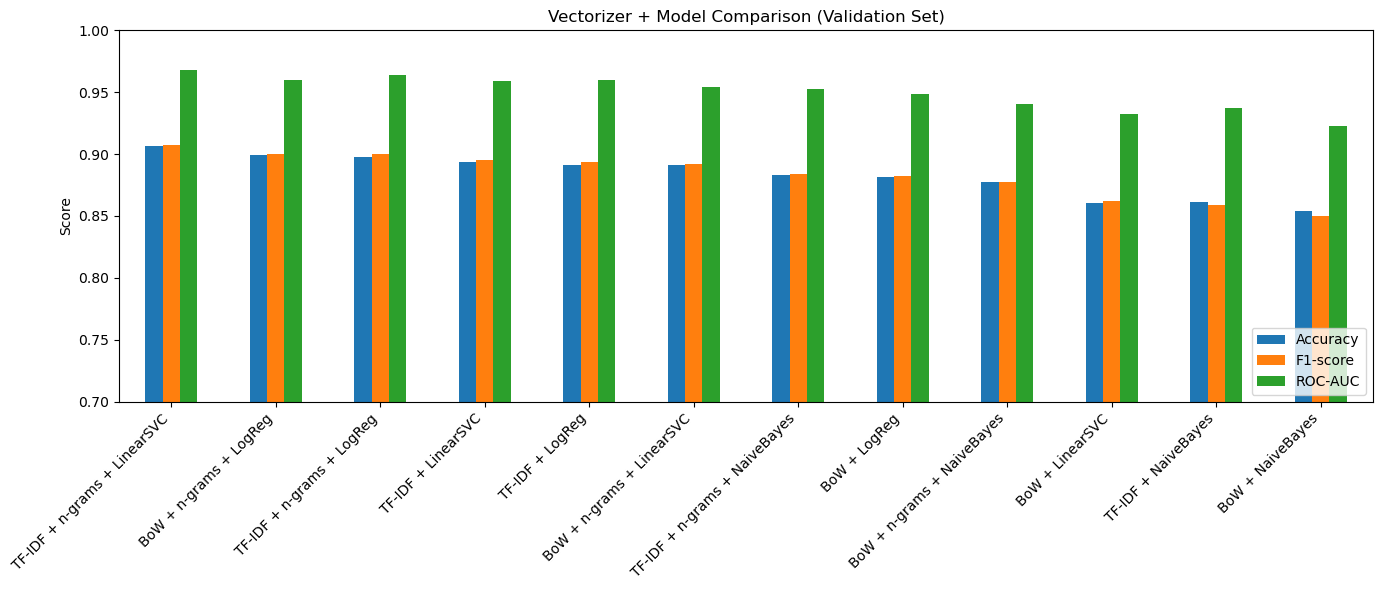

In [93]:
# Plot F1-score of every combination
comparison_df["Combination"] = comparison_df["Vectorizer"] + " + " + comparison_df["Model"]
comparison_df.plot(
    x="Combination", y=["Accuracy", "F1-score", "ROC-AUC"],
    kind="bar", figsize=(14, 6)
)
plt.title("Vectorizer + Model Comparison (Validation Set)")
plt.ylabel("Score")
plt.xlabel("")
# Zoom the y-axis to 0.7-1 so differences are visible
plt.ylim(0.7, 1)
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. Hyperparameter Tuning

The **top 3** combinations are tuned, because small differences on a single validation split can be noise.

- **Data:** train + validation, with 5-fold stratified cross-validation
- **Scoring:** F1-score of the positive class
- **Test set:** not used here

| Parameter | Values | Applies to |
|-----------|--------|-----------|
| `min_df` | 2, 5 | All vectorizers |
| `max_df` | 0.9, 1.0 | All vectorizers |
| `C` | 0.1, 1, 10 | Logistic Regression |
| `C` | 0.1, 0.5, 1 | Linear SVC |
| `alpha` | 0.1, 0.5, 1.0 | Naive Bayes |

The n-gram range stays fixed for each combination because it was already compared in the previous step.

In [94]:
# Combine train and validation data for cross-validated tuning
X_trainval_text = pd.concat([X_train_text, X_val_text])
y_trainval = pd.concat([y_train, y_val])

# Vectorizer hyperparameters to search
vec_params = {
    "vec__min_df": [2, 5],
    "vec__max_df": [0.9, 1.0],
}
# Model hyperparameters to search (depends on the model)
model_params = {
    "LogReg":     {"clf__C": [0.1, 1, 10]},
    "NaiveBayes": {"clf__alpha": [0.1, 0.5, 1.0]},
    "LinearSVC":  {"clf__C": [0.1, 0.5, 1]},
}

# Tuning metric: F1-score of the positive class
f1_scorer = make_scorer(f1_score, pos_label=positive_label)
# 5-fold stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Only the top 3 combinations from the comparison are tuned
top_n = 3
# Collects the tuning results
tuned = []

# Grid search for each of the top combinations
for _, row in comparison_df.head(top_n).iterrows():
    vec_name, model_name = row["Vectorizer"], row["Model"]
    print(f"\nTuning: {vec_name} + {model_name}")

    # Exhaustive search over vectorizer and model parameters
    grid = GridSearchCV(
        build_pipeline(vec_name, model_name),
        param_grid={**vec_params, **model_params[model_name]},
        scoring=f1_scorer,
        cv=cv,
        n_jobs=-1,
        refit=True,  # best params are refit on all of train + validation
    )
    # Run the search
    grid.fit(X_trainval_text, y_trainval)

    print("Best params:", grid.best_params_)
    print("Best CV F1 :", round(grid.best_score_, 4))

    # Save the tuning result
    tuned.append({
        "Vectorizer": vec_name,
        "Model": model_name,
        "Best CV F1": grid.best_score_,
        "Best params": grid.best_params_,
        "estimator": grid.best_estimator_,
    })

# Rank the tuned models by CV F1-score
tuned_df = (
    pd.DataFrame(tuned)
    .sort_values(by="Best CV F1", ascending=False)
    .reset_index(drop=True)
)
print("\nTuned comparison (CV F1):")
print(tuned_df[["Vectorizer", "Model", "Best CV F1", "Best params"]].round(4))


Tuning: TF-IDF + n-grams + LinearSVC
Best params: {'clf__C': 0.5, 'vec__max_df': 0.9, 'vec__min_df': 2}
Best CV F1 : 0.9095

Tuning: BoW + n-grams + LogReg
Best params: {'clf__C': 0.1, 'vec__max_df': 0.9, 'vec__min_df': 2}
Best CV F1 : 0.9008

Tuning: TF-IDF + n-grams + LogReg
Best params: {'clf__C': 10, 'vec__max_df': 0.9, 'vec__min_df': 5}
Best CV F1 : 0.9083

Tuned comparison (CV F1):
         Vectorizer      Model  Best CV F1  \
0  TF-IDF + n-grams  LinearSVC      0.9095   
1  TF-IDF + n-grams     LogReg      0.9083   
2     BoW + n-grams     LogReg      0.9008   

                                             Best params  
0  {'clf__C': 0.5, 'vec__max_df': 0.9, 'vec__min_df': 2}  
1   {'clf__C': 10, 'vec__max_df': 0.9, 'vec__min_df': 5}  
2  {'clf__C': 0.1, 'vec__max_df': 0.9, 'vec__min_df': 2}  


### Tuning Result

| Vectorizer | Model | Best CV F1 | Best parameters |
|-----------|-------|-----------|-----------------|
| TF-IDF + n-grams | LinearSVC | 0.9095 | 'clf__C': 0.5, 'vec__max_df': 0.9, 'vec__min_df': 2 |

**Final model:** [Vectorizer] + [Model], chosen by cross-validated F1-score.

## 9. Final Evaluation on the Test Set

The selected model is evaluated on the test set **once**. The test set was never used for model selection or tuning, so this is an honest estimate of real-world performance.

| Metric | Positive | Negative |
|--------|-------|-------|
| Precision | 0.9 | 0.92 |
| Recall | 0.92 | 0.9 |
| F1-score | 0.91 | 0.91 |

The confusion matrix shows [which kind of error is more common: false positives or false negatives].


Final model: TF-IDF + n-grams + LinearSVC
Params: {'clf__C': 0.5, 'vec__max_df': 0.9, 'vec__min_df': 2}
              precision    recall  f1-score   support

    negative       0.92      0.90      0.91      4940
    positive       0.90      0.92      0.91      4977

    accuracy                           0.91      9917
   macro avg       0.91      0.91      0.91      9917
weighted avg       0.91      0.91      0.91      9917

Test ROC-AUC: 0.9702


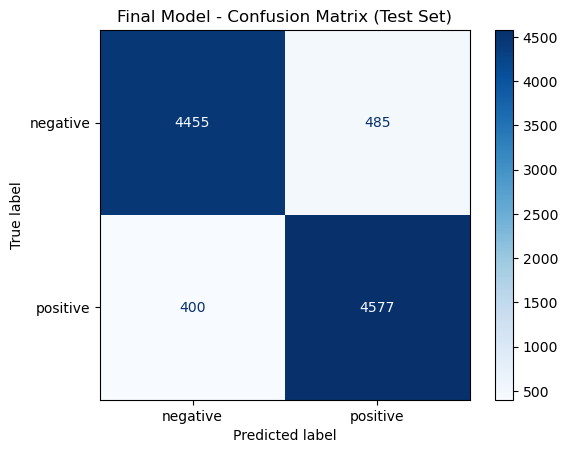

In [95]:
# Pick the best tuned model (highest CV F1-score)
final_row = tuned_df.iloc[0]
final_pipeline = final_row["estimator"]
print(f"\nFinal model: {final_row['Vectorizer']} + {final_row['Model']}")
print("Params:", final_row["Best params"])

# Evaluate the final model on the untouched test set
X_test_text = test_df[best_method]
y_test_pred = final_pipeline.predict(X_test_text)
y_test_score = get_positive_scores(final_pipeline, X_test_text)

# Per-class precision, recall and F1-score
print(classification_report(y_test, y_test_pred))
# ROC-AUC on the test set
print("Test ROC-AUC:", round(
    roc_auc_score((y_test == positive_label).astype(int), y_test_score), 4
))

# Confusion matrix of true vs predicted labels
cm = confusion_matrix(y_test, y_test_pred, labels=final_pipeline.classes_)
# Plot the confusion matrix
ConfusionMatrixDisplay(cm, display_labels=final_pipeline.classes_).plot(cmap="Blues")
plt.title("Final Model - Confusion Matrix (Test Set)")
plt.show()

# Save the final pipeline

In [96]:
# Save the fitted pipeline (vectorizer + model) to disk for later use
joblib.dump(final_pipeline, "final_sentiment_pipeline.joblib")

['final_sentiment_pipeline.joblib']

## 10. Model Interpretation

The learned feature weights show which words and phrases push a review toward each class.

- **Positive weight:** pushes the prediction toward *positive* sentiment
- **Negative weight:** pushes the prediction toward *negative* sentiment

**Findings**
- Strongest positive features: excellent, perfect, favorite
- Strongest negative features: worst, awful, waste
- Negation bigrams such as [not good] appear among the strongest features, which confirms that keeping negations and using n-grams was worthwhile.

> Weights show association with a class, not causation.

Top features pushing toward POSITIVE sentiment:
     Feature  Coefficient
   excellent        3.319
       great        3.279
     perfect        2.808
     amazing        2.425
   wonderful        2.395
        best        2.321
    must see        2.306
    favorite        2.254
   brilliant        2.186
         fun        2.177
   enjoyable        2.172
   hilarious        2.112
       loved        2.100
       10 10        2.001
       today        1.949
    one best        1.932
entertaining        1.927
      subtle        1.923
     enjoyed        1.922
      superb        1.914

Top features pushing toward NEGATIVE sentiment:
       Feature  Coefficient
         worst       -4.760
         awful       -4.124
           bad       -3.384
        boring       -3.334
         waste       -3.211
          poor       -3.072
      terrible       -2.840
         fails       -2.658
 disappointing       -2.611
      horrible       -2.608
disappointment       -2.608
       nothing       

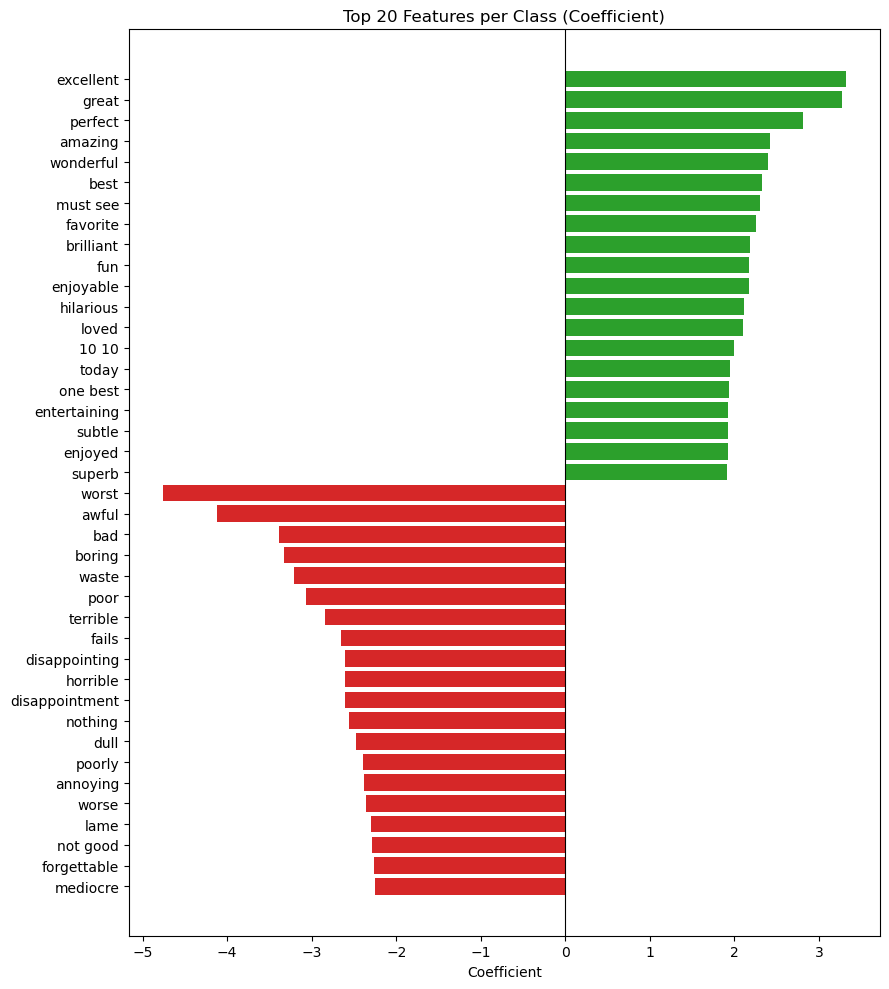


Negation-related features among the strongest ones: ['not good']


In [97]:
# Get the fitted vectorizer and classifier from the pipeline
vec = final_pipeline.named_steps["vec"]
clf = final_pipeline.named_steps["clf"]
features = np.array(vec.get_feature_names_out())

# One weight per feature. Positive weight pushes toward classes_[1].
if hasattr(clf, "coef_"):                      # LogReg, LinearSVC
    weights = clf.coef_[0]
    weight_name = "Coefficient"
elif hasattr(clf, "feature_log_prob_"):        # NaiveBayes
    weights = clf.feature_log_prob_[1] - clf.feature_log_prob_[0]
    weight_name = "Log-prob ratio"
else:
    raise ValueError("This model type has no feature weights to interpret.")

# Make sure a positive weight always means the POSITIVE sentiment class
if clf.classes_[1] != positive_label:
    weights = -weights

# Feature indices sorted from lowest to highest weight
order = np.argsort(weights)
# Number of top features shown per class
top_n = 20
top_neg_idx = order[:top_n]                    # most negative first
top_pos_idx = order[-top_n:][::-1]             # most positive first

# Tables of the top positive and negative features
top_pos_df = pd.DataFrame({"Feature": features[top_pos_idx], weight_name: weights[top_pos_idx]})
top_neg_df = pd.DataFrame({"Feature": features[top_neg_idx], weight_name: weights[top_neg_idx]})

# Print both tables
print("Top features pushing toward POSITIVE sentiment:")
print(top_pos_df.round(3).to_string(index=False))
print("\nTop features pushing toward NEGATIVE sentiment:")
print(top_neg_df.round(3).to_string(index=False))

# Plot both sides in one chart
plot_df = pd.concat([top_neg_df.iloc[::-1], top_pos_df.iloc[::-1]])
# Red bars for negative features, green bars for positive
colors = ["tab:red"] * top_n + ["tab:green"] * top_n
plt.figure(figsize=(9, 10))
plt.barh(plot_df["Feature"], plot_df[weight_name], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title(f"Top {top_n} Features per Class ({weight_name})")
plt.xlabel(weight_name)
plt.tight_layout()
plt.show()

# Do negation bigrams show up among the strongest features?
strong_idx = np.concatenate([top_pos_idx, top_neg_idx])
negation_feats = [f for f in features[strong_idx] if f.split()[0] in {"not", "no", "nor", "never"}]
print("\nNegation-related features among the strongest ones:", negation_feats)

## 11. Threshold and Calibration Analysis

### Threshold analysis
A classifier does not have to use a 0.5 cutoff. Moving the threshold trades precision against recall.

- The best threshold is chosen using **out-of-fold predictions** on train + validation.
- It is then applied to the test set, so the test set stays untouched during selection.

**Result:** best threshold = 0.475, close to / different from the default 0.5.

### Calibration
A calibration curve checks whether a predicted probability of 0.8 really means about 80% of such reviews are positive.

- Brier score: 0.0659 (lower is better)
- The model is well calibrated.

If the final model is LinearSVC, probabilities come from a `CalibratedClassifierCV` wrapper.

In [98]:
# Make sure the pipeline outputs probabilities (LinearSVC is wrapped in CalibratedClassifierCV with sigmoid calibration)
if hasattr(final_pipeline, "predict_proba"):
    prob_pipeline = clone(final_pipeline)          # LogReg / NaiveBayes
else:                                              # LinearSVC -> calibrate it
    prob_pipeline = Pipeline([
        ("vec", clone(final_pipeline.named_steps["vec"])),
        ("clf", CalibratedClassifierCV(
            clone(final_pipeline.named_steps["clf"]), cv=5, method="sigmoid"
        )),
    ])

# Column of the positive class in the predict_proba output
pos_idx = list(final_pipeline.classes_).index(positive_label)
# Binary labels (1 = positive) for train + validation and for test
y_trainval_bin = (y_trainval == positive_label).astype(int).to_numpy()
y_test_bin = (y_test == positive_label).astype(int).to_numpy()

Best threshold by out-of-fold F1: 0.475 (F1 = 0.9098)


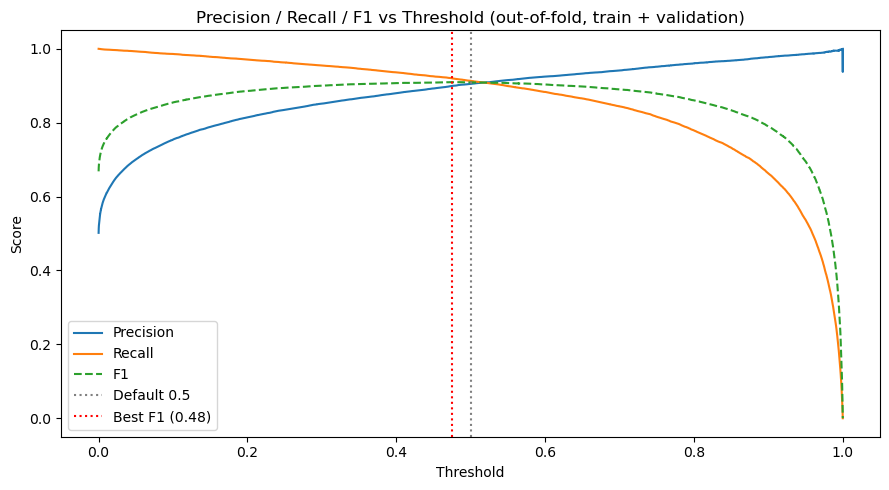

In [99]:
# Out-of-fold positive-class probabilities on train + validation (avoids leakage)
oof_prob = cross_val_predict(
    prob_pipeline, X_trainval_text, y_trainval,
    cv=cv, method="predict_proba", n_jobs=-1
)[:, pos_idx]

# Precision and recall at every possible threshold
precision, recall, thresholds = precision_recall_curve(y_trainval_bin, oof_prob)
p, r = precision[:-1], recall[:-1]                 # align with thresholds
# F1-score at each threshold (0 where precision + recall = 0)
f1_curve = np.divide(2 * p * r, p + r, out=np.zeros_like(p), where=(p + r) > 0)

# Threshold with the highest out-of-fold F1-score
best_thr = thresholds[np.argmax(f1_curve)]
print(f"Best threshold by out-of-fold F1: {best_thr:.3f} (F1 = {f1_curve.max():.4f})")

# Plot precision, recall and F1-score against the threshold
plt.figure(figsize=(9, 5))
plt.plot(thresholds, p, label="Precision")
plt.plot(thresholds, r, label="Recall")
plt.plot(thresholds, f1_curve, label="F1", linestyle="--")
plt.axvline(0.5, color="gray", linestyle=":", label="Default 0.5")
plt.axvline(best_thr, color="red", linestyle=":", label=f"Best F1 ({best_thr:.2f})")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision / Recall / F1 vs Threshold (out-of-fold, train + validation)")
plt.legend()
plt.tight_layout()
plt.show()

In [100]:
# Use a model fitted on train + validation (the calibrated wrapper is fitted here for LinearSVC)
if hasattr(final_pipeline, "predict_proba"):
    fitted_prob_pipeline = final_pipeline          # already fitted on train + validation
else:
    fitted_prob_pipeline = prob_pipeline.fit(X_trainval_text, y_trainval)

# Positive-class probabilities on the test set
test_prob = fitted_prob_pipeline.predict_proba(X_test_text)[:, pos_idx]

# Evaluate several thresholds on the test set
rows = []
for thr in [0.3, 0.4, 0.5, 0.6, 0.7, best_thr]:
    pred = (test_prob >= thr).astype(int)
    rows.append({
        "Threshold": round(float(thr), 3),
        "Accuracy": accuracy_score(y_test_bin, pred),
        "Precision": precision_score(y_test_bin, pred, zero_division=0),
        "Recall": recall_score(y_test_bin, pred, zero_division=0),
        "F1-score": f1_score(y_test_bin, pred, zero_division=0),
    })
# Table of results sorted by threshold, without duplicate thresholds
threshold_table = (
    pd.DataFrame(rows).drop_duplicates(subset="Threshold").sort_values("Threshold")
)
# Print the results
print("\nTest-set metrics at different thresholds:")
print(threshold_table.round(4).to_string(index=False))


Test-set metrics at different thresholds:
 Threshold  Accuracy  Precision  Recall  F1-score
     0.300    0.8980     0.8568  0.9566    0.9039
     0.400    0.9060     0.8823  0.9379    0.9092
     0.475    0.9094     0.9014  0.9202    0.9107
     0.500    0.9094     0.9067  0.9136    0.9101
     0.600    0.9087     0.9270  0.8881    0.9071
     0.700    0.8991     0.9463  0.8469    0.8939


# Calibration curve


Brier score (lower is better): 0.0659


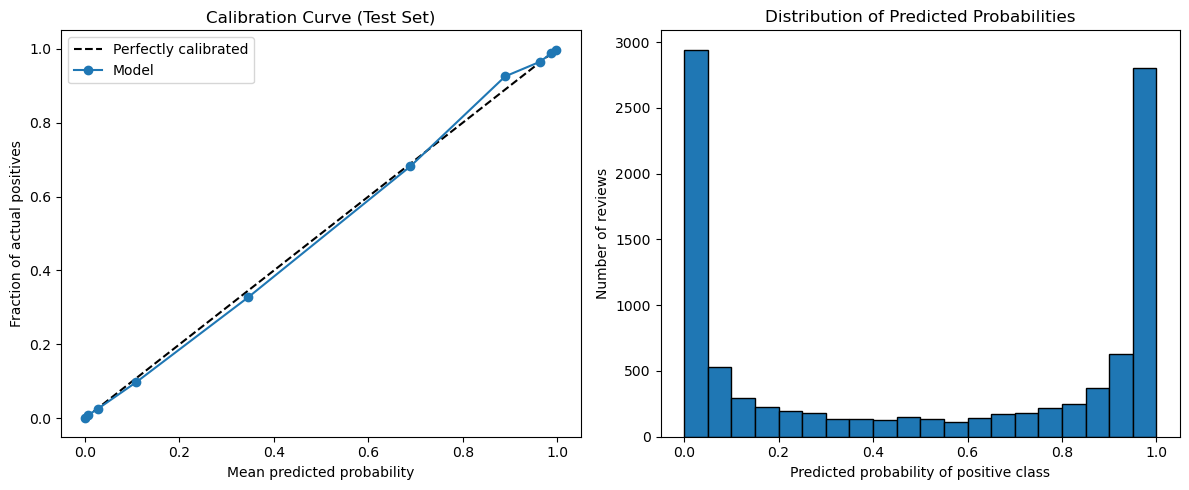

In [101]:
# Calibration curve points: observed fraction of positives vs mean predicted probability (10 quantile bins)
frac_pos, mean_pred = calibration_curve(y_test_bin, test_prob, n_bins=10, strategy="quantile")
# Brier score: mean squared error of the probabilities (lower is better)
brier = brier_score_loss(y_test_bin, test_prob)
print(f"\nBrier score (lower is better): {brier:.4f}")

# Left: calibration curve | Right: histogram of predicted probabilities
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
# Diagonal line = perfect calibration
ax[0].plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
ax[0].plot(mean_pred, frac_pos, marker="o", label="Model")
ax[0].set_xlabel("Mean predicted probability")
ax[0].set_ylabel("Fraction of actual positives")
ax[0].set_title("Calibration Curve (Test Set)")
ax[0].legend()

# Histogram of the predicted probabilities
ax[1].hist(test_prob, bins=20, edgecolor="black")
ax[1].set_xlabel("Predicted probability of positive class")
ax[1].set_ylabel("Number of reviews")
ax[1].set_title("Distribution of Predicted Probabilities")

plt.tight_layout()
plt.show()

## 12. Conclusion

**Summary**
- Cleaning kept negation words and fixed issues such as `<br />` merging words.
- **[Basic]** normalization performed best, so stemming and lemmatization were not needed.
- The best pipeline was **[TF-IDF + n-grams] + [LinearSVC]**, with tuned parameters ['clf__C': 0.5, 'vec__max_df': 0.9, 'vec__min_df': 2].

**Limitations**
- Bag-of-words models ignore word order beyond 2-grams and miss context.
- Sarcasm and mixed reviews (*"great acting, terrible plot"*) are often misclassified.
- Results come from a single dataset and may not transfer to other domains.

**Future work**
- Error analysis of misclassified reviews
- Word embeddings (Word2Vec / GloVe) or a fine-tuned transformer (e.g. DistilBERT) for comparison
- Wrapping the cleaning step into the pipeline with `FunctionTransformer`
- A Streamlit demo for live predictions